# Solución de Ecuaciones Diferenciales Ordinarias con la Transformada de Fourier
**Basado en el material de FIUSAC (Prof. José Saquimuz)**

Este cuaderno automatiza el proceso simbólico para resolver EDOs lineales de coeficientes constantes utilizando **SymPy** y la **Transformada de Fourier**:
1. Transformación del lado izquierdo (derivadas) al dominio de frecuencia $\omega$.
2. Transformación del lado derecho (término forzador $f(t)$).
3. Despeje algebraico de $Y(\omega)$.
4. Descomposición en fracciones parciales / residuos.
5. Transformada Inversa de Fourier para obtener $y_p(t)$.
6. Solución de la ecuación homogénea para $y_c(t)$ y graficación.



In [2]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt

# Configuración para mostrar ecuaciones formateadas en LaTeX
sp.init_printing(use_latex=True)

# Declaración de variables simbólicas principales
t, w = sp.symbols('t w', real=True)
i_complex = sp.I # Unidad imaginaria i

In [3]:
def resolver_edo_fourier(lhs_expr, rhs_expr, y_func, t_var, w_var):
    """
    Resuelve una EDO lineal con coeficientes constantes por Transformada de Fourier.
    """
    Y = sp.Function('Y')(w_var)
    
    print("--------------------------------------------------")
    print("PASO 1: Transformar el Lado Izquierdo (Propiedad de Derivada)")
    print("--------------------------------------------------")
    lhs_expanded = lhs_expr.expand()
    substitutions = {}
    
    # Sustituir derivadas d^n y / dt^n por (i*w)^n * Y(w)
    for term in lhs_expanded.atoms(sp.Derivative):
        if term.expr == y_func:
            order = term.derivative_count
            substitutions[term] = (i_complex * w_var)**order * Y
            
    substitutions[y_func] = Y
    lhs_W = lhs_expanded.subs(substitutions)
    display(sp.Eq(sp.symbols('LHS(\\omega)'), lhs_W))
    
    print("\n--------------------------------------------------")
    print("PASO 2: Transformar el Lado Derecho f(t)")
    print("--------------------------------------------------")
    # conds='none' evita que SymPy devuelva un objeto Piecewise con condiciones de convergencia
    rhs_W = sp.integrate(rhs_expr * sp.exp(-i_complex * w_var * t_var), (t_var, -sp.oo, sp.oo), conds='none')
    rhs_W = sp.simplify(rhs_W) # Simplifica a 1 / (w^2 + 1)
    display(sp.Eq(sp.symbols('RHS(\\omega)'), rhs_W))
    
    print("\n--------------------------------------------------")
    print("PASO 3: Despejar Y(\\omega)")
    print("--------------------------------------------------")
    eq_fourier = sp.Eq(lhs_W, rhs_W)
    sol_Y = sp.solve(eq_fourier, Y)[0]
    sol_Y = sp.simplify(sol_Y)
    display(sp.Eq(Y, sol_Y))
    
    print("\n--------------------------------------------------")
    print("PASO 4: Descomposición en Fracciones Parciales")
    print("--------------------------------------------------")
    # Expansión en fracciones parciales sobre w
    sol_Y_pf = sp.apart(sol_Y, w_var)
    display(sp.Eq(Y, sol_Y_pf))
    
    return sol_Y, sol_Y_pf

### Ejemplo 1: Ecuación de primer orden
Resolver la ecuación diferencial[cite: 1]:
$$y' + y = \frac{1}{2} e^{-|t|}, \quad -\infty < t < \infty$$

In [7]:
# Definición del problema
y = sp.Function('y')(t)
lhs1 = y.diff(t) + 2*y
rhs1 =  sp.exp(-1*t) * sp.Heaviside(t)  # f(t) = e^(-t) * H(t)

print("=== RESOLVIENDO EJEMPLO 1 ===")
Y1_w, Y1_pf = resolver_edo_fourier(lhs1, rhs1, y, t, w)

# Formulario / Inversa explícita paso a paso (según documento)[cite: 1]:
# Y(w) = 1 / (4*(1 - i*w)) + 1 / (4*(1 + i*w)) + 1 / (2*(1 + i*w)^2)
# F^-1 -> (1/4)*e^t * H(-t) + (1/4)*e^-t * H(t) + (1/2)*t*e^-t * H(t)
y_p1 = (1/sp.sympify(4))*sp.exp(-sp.Abs(t)) + sp.Rational(1, 2)*t*sp.exp(-t)*sp.Heaviside(t)

print("\nSolución particular obtenida[cite: 1, 2]:")
display(sp.Eq(sp.symbols('y_p(t)'), y_p1))

# Solución complementaria: y' + y = 0 => y_c(t) = A * e^(-t)[cite: 2]
C1 = sp.Symbol('A')
y_c1 = C1 * sp.exp(-t)

print("\nSolución General[cite: 2]:")
y_gen1 = y_c1 + y_p1
display(sp.Eq(y, y_gen1))

=== RESOLVIENDO EJEMPLO 1 ===
--------------------------------------------------
PASO 1: Transformar el Lado Izquierdo (Propiedad de Derivada)
--------------------------------------------------



--------------------------------------------------
PASO 2: Transformar el Lado Derecho f(t)
--------------------------------------------------



--------------------------------------------------
PASO 3: Despejar Y(\omega)
--------------------------------------------------



--------------------------------------------------
PASO 4: Descomposición en Fracciones Parciales
--------------------------------------------------



Solución particular obtenida[cite: 1, 2]:



Solución General[cite: 2]:


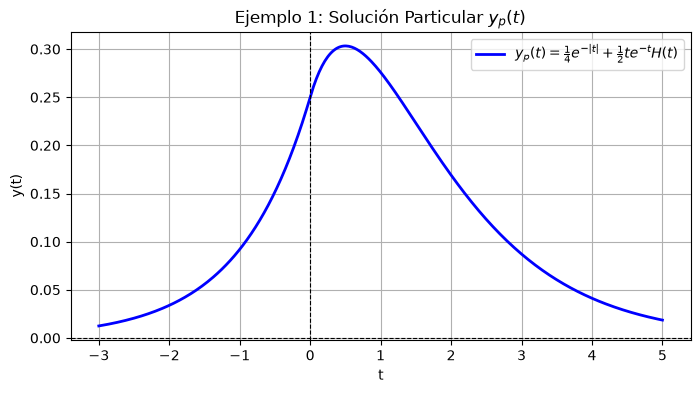

In [36]:
# Convertir a función numérica para graficar y_p(t)
y_p1_func = sp.lambdify(t, y_p1.subs(sp.Heaviside(t), 1), modules=['numpy'])

t_vals = np.linspace(-3, 5, 400)
y_vals = np.where(t_vals >= 0, 0.25*np.exp(-np.abs(t_vals)) + 0.5*t_vals*np.exp(-t_vals), 0.25*np.exp(t_vals))

plt.figure(figsize=(8, 4))
plt.plot(t_vals, y_vals, label=r'$y_p(t) = \frac{1}{4}e^{-|t|} + \frac{1}{2}t e^{-t}H(t)$', color='blue', lw=2)
plt.axhline(0, color='black', linewidth=0.8, linestyle='--')
plt.axvline(0, color='black', linewidth=0.8, linestyle='--')
plt.title('Ejemplo 1: Solución Particular $y_p(t)$')
plt.xlabel('t')
plt.ylabel('y(t)')
plt.grid(True)
plt.legend()
plt.show()

### Ejemplo 2: Respuesta al impulso ($\delta(t)$) mediante la Fórmula de Residuos
Resolver la ecuación[cite: 3]:
$$y'' + 3y' + 2y = \delta(t)$$

El documento utiliza la fórmula de expansión por residuos[cite: 3]:
$$\mathcal{F}^{-1}\left[\frac{P(\omega)}{Q(\omega)}\right] = i \sum_{k=1}^n \frac{P(\omega_k)}{Q'(\omega_k)} e^{i \omega_k t}$$
donde $\omega_k$ son las raíces simples del denominador $Q(\omega)$[cite: 3].

In [37]:
# Lado izquierdo y derecho del Ejemplo 2
lhs2 = y.diff(t, 2) + 3*y.diff(t) + 2*y
rhs2 = sp.DiracDelta(t)

# Definimos 'w_c' sin restricción 'real=True' para permitir raíces complejas
w_c = sp.Symbol('w')

# Denominador Q(w) = -w^2 + 3*i*w + 2
Q_w = -w_c**2 + 3*i_complex*w_c + 2
P_w = 1

# Cálculo de raíces simples de Q(w) = 0
raices = sp.solve(Q_w, w_c)
print("Raíces simples de Q(omega):", raices)

# Derivada Q'(w)
Q_prime = sp.diff(Q_w, w_c)

# Aplicación de la fórmula de residuos (A) del documento de FIUSAC
y_p2_terms = []
for w_k in raices:
    term = (P_w / Q_prime.subs(w_c, w_k)) * sp.exp(i_complex * w_k * t)
    y_p2_terms.append(term)

# y(t) = i * sum( (P(w_k) / Q'(w_k)) * e^(i*w_k*t) ) * H(t)
y_p2 = i_complex * sum(y_p2_terms) * sp.Heaviside(t)
y_p2 = sp.expand(y_p2)

print("\nSolución Particular mediante Residuos:")
display(sp.Eq(sp.symbols('y_p(t)'), y_p2))

Raíces simples de Q(omega): [I, 2*I]

Solución Particular mediante Residuos:


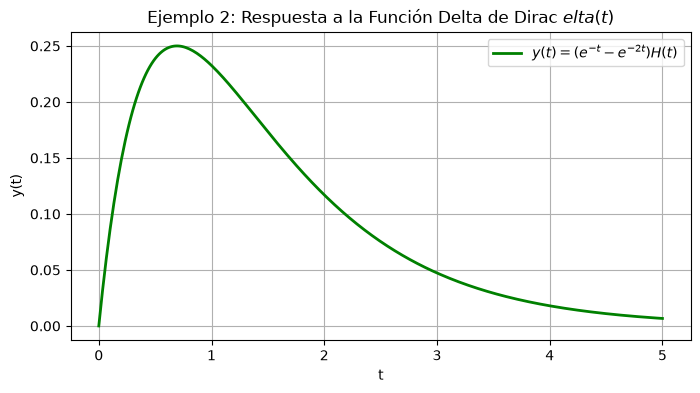

In [38]:
# Graficación de la respuesta impulsiva y(t) = (e^-t - e^-2t) H(t)[cite: 3]
t_num = np.linspace(0, 5, 300)
y_num = np.exp(-t_num) - np.exp(-2*t_num)

plt.figure(figsize=(8, 4))
plt.plot(t_num, y_num, color='green', lw=2, label=r'$y(t) = (e^{-t} - e^{-2t})H(t)$')
plt.title('Ejemplo 2: Respuesta a la Función Delta de Dirac $elta(t)$')
plt.xlabel('t')
plt.ylabel('y(t)')
plt.grid(True)
plt.legend()
plt.show()

### Ejemplo 3: Análisis de Circuito RC[cite: 4]
Dado un circuito RC sometido a un impulso de corriente $i(t) = Q\delta(t)$[cite: 4]:
$$i_C(t) = Q\delta(t) - \frac{Q}{RC} e^{-t/RC} H(t)$$


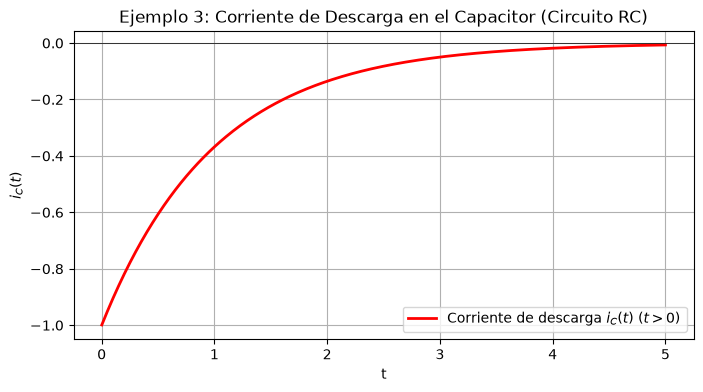

In [39]:
# Parámetros del ejercicio: Q = R = C = 1[cite: 4]
Q_val, R_val, C_val = 1.0, 1.0, 1.0

t_circ = np.linspace(0.001, 5, 400)
# Componente continua/decaimiento exponencial para t > 0
i_C_continua = -(Q_val / (R_val * C_val)) * np.exp(-t_circ / (R_val * C_val))

plt.figure(figsize=(8, 4))
plt.plot(t_circ, i_C_continua, 'r-', lw=2, label=r'Corriente de descarga $i_C(t)$ ($t > 0$)')
plt.axhline(0, color='k', lw=0.5)
plt.title('Ejemplo 3: Corriente de Descarga en el Capacitor (Circuito RC)')
plt.xlabel('t')
plt.ylabel(r'$i_C(t)$')
plt.grid(True)
plt.legend()
plt.show()

RESOLVIENDO 2y' + 3y = exp(-2t) H(t) POR FOURIER
Raíces simples de Q(omega): [3*I/2, 2*I]

Solución Particular (y_p):



Solución Complementaria (y_c):



Solución General:


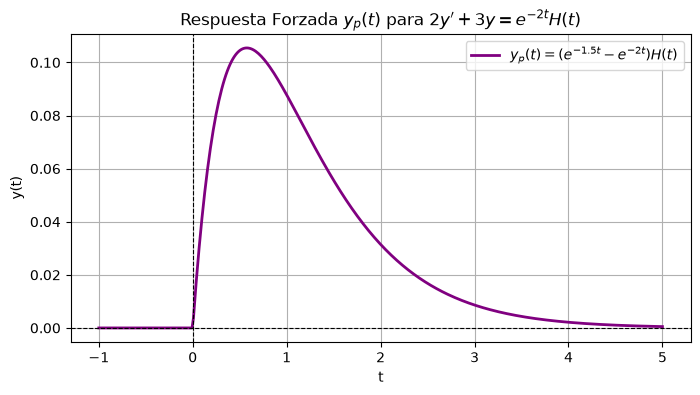

In [40]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt

# Definición de variables simbólicas
t = sp.Symbol('t', real=True)
w_c = sp.Symbol('w') # Variable compleja para el cálculo de residuos
i_complex = sp.I

# 1. Definición de la EDO: 2*y' + 3*y = exp(-2*t)*H(t)
y = sp.Function('y')(t)
lhs = 2*y.diff(t) + 3*y
rhs = sp.exp(-2*t) * sp.Heaviside(t)

print("==================================================")
print("RESOLVIENDO 2y' + 3y = exp(-2t) H(t) POR FOURIER")
print("==================================================")

# 2. Denominador Q(w) y Numerador P(w) en la frecuencia
# (2*i*w + 3)*(i*w + 2) = -2*w^2 + 7*i*w + 6
Q_w = -2*w_c**2 + 7*i_complex*w_c + 6
P_w = 1

# 3. Raíces simples de Q(w) = 0
raices = sp.solve(Q_w, w_c)
print("Raíces simples de Q(omega):", raices)

# 4. Aplicación de la fórmula de residuos A del documento
Q_prime = sp.diff(Q_w, w_c)

y_p_terms = []
for w_k in raices:
    term = (P_w / Q_prime.subs(w_c, w_k)) * sp.exp(i_complex * w_k * t)
    y_p_terms.append(term)

# Solución particular y_p(t)
y_p = sp.expand(i_complex * sum(y_p_terms) * sp.Heaviside(t))

print("\nSolución Particular (y_p):")
display(sp.Eq(sp.symbols('y_p(t)'), y_p))

# 5. Solución Complementaria (EDO homogénea 2y' + 3y = 0)
A = sp.Symbol('A')
y_c = A * sp.exp(-sp.Rational(3, 2) * t)

print("\nSolución Complementaria (y_c):")
display(sp.Eq(sp.symbols('y_c(t)'), y_c))

# 6. Solución General y(t) = y_c(t) + y_p(t)
y_gen = y_c + y_p
print("\nSolución General:")
display(sp.Eq(y, y_gen))

# --------------------------------------------------
# 7. Graficación de la Solución Particular y_p(t)
# --------------------------------------------------
t_vals = np.linspace(-1, 5, 400)
# Evaluamos y_p(t) para t >= 0
y_p_vals = np.where(t_vals >= 0, np.exp(-1.5 * t_vals) - np.exp(-2.0 * t_vals), 0)

plt.figure(figsize=(8, 4))
plt.plot(t_vals, y_p_vals, color='purple', lw=2, label=r'$y_p(t) = (e^{-1.5t} - e^{-2t})H(t)$')
plt.axhline(0, color='black', linewidth=0.8, linestyle='--')
plt.axvline(0, color='black', linewidth=0.8, linestyle='--')
plt.title(r'Respuesta Forzada $y_p(t)$ para $2y^{\prime} + 3y = e^{-2t}H(t)$')
plt.xlabel('t')
plt.ylabel('y(t)')
plt.grid(True)
plt.legend()
plt.show()

In [41]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt

# Intentar usar 'display' si se ejecuta dentro de Jupyter Notebook
try:
    from IPython.display import display
except ImportError:
    display = print

def resolver_edo_fourier_plantilla(lhs_expr, rhs_expr, y_func, t_var, t_min=-1, t_max=5):
    """
    PLANTILLA GENERAL PARA RESOLVER EDOs LINEALES CON TRANSFORMADA DE FOURIER
    
    Parámetros:
      lhs_expr : Lado izquierdo de la EDO (ej. 2*y.diff(t) + 3*y o y.diff(t,2) + 3*y.diff(t) + 2*y)
      rhs_expr : Lado derecho f(t) (ej. sp.exp(-2*t)*sp.Heaviside(t), sp.DiracDelta(t), etc.)
      y_func   : Función incógnita sympy, ej. y = sp.Function('y')(t)
      t_var    : Variable del tiempo (t)
      t_min, t_max : Intervalo para graficar
    """
    w_c = sp.Symbol('w') # Variable de frecuencia en el dominio complejo
    i_complex = sp.I
    Y = sp.Function('Y')(w_c)
    
    print("======================================================================")
    print("PASO 1: Transformar el Lado Izquierdo al Dominio de Frecuencia")
    print("======================================================================")
    lhs_expanded = lhs_expr.expand()
    subs_lhs = {}
    for term in lhs_expanded.atoms(sp.Derivative):
        if term.expr == y_func:
            order = term.derivative_count
            subs_lhs[term] = (i_complex * w_c)**order * Y
    subs_lhs[y_func] = Y
    lhs_W = lhs_expanded.subs(subs_lhs)
    coef_Y = lhs_W.coeff(Y)
    display(sp.Eq(sp.symbols('LHS(\\omega)'), lhs_W))
    
    print("\n======================================================================")
    print("PASO 2: Transformar el Lado Derecho f(t)")
    print("======================================================================")
    if rhs_expr.has(sp.DiracDelta):
        # F[delta(t)] = 1
        rhs_W = sp.sympify(1)
    else:
        rhs_W = sp.integrate(rhs_expr * sp.exp(-i_complex * w_c * t_var), (t_var, -sp.oo, sp.oo), conds='none')
        rhs_W = sp.simplify(rhs_W)
    display(sp.Eq(sp.symbols('RHS(\\omega)'), rhs_W))
    
    print("\n======================================================================")
    print("PASO 3: Despejar Y(\\omega)")
    print("======================================================================")
    Y_w = sp.simplify(rhs_W / coef_Y)
    display(sp.Eq(Y, Y_w))
    
    print("\n======================================================================")
    print("PASO 4: Inversa de Fourier para la Solución Particular y_p(t)")
    print("======================================================================")
    num, den = sp.fraction(Y_w)
    P_w, Q_w = num, den
    Q_prime = sp.diff(Q_w, w_c)
    raices = sp.solve(Q_w, w_c)
    
    # Verificar si todas las raíces son simples (Q'(w_k) != 0)
    raices_simples = True
    if raices:
        for r in raices:
            if Q_prime.subs(w_c, r) == 0:
                raices_simples = False
                break
                
    if raices and raices_simples:
        print("-> Método de Residuos (Fórmula A del PDF para raíces simples):")
        y_p_terms = []
        for w_k in raices:
            term = (P_w.subs(w_c, w_k) / Q_prime.subs(w_c, w_k)) * sp.exp(i_complex * w_k * t_var)
            y_p_terms.append(term)
        y_p = sp.expand(i_complex * sum(y_p_terms) * sp.Heaviside(t_var))
    else:
        print("-> Descomposición en Fracciones Parciales / Inversa Directa:")
        Y_pf = sp.apart(Y_w, w_c)
        display(sp.Eq(sp.symbols('Y_{frac}(\\omega)'), Y_pf))
        y_p = sp.inverse_fourier_transform(Y_w, w_c, t_var)
        
    display(sp.Eq(sp.symbols('y_p(t)'), y_p))
    
    print("\n======================================================================")
    print("PASO 5: Solución Complementaria y_c(t) y Solución General y(t)")
    print("======================================================================")
    m = sp.Symbol('m')
    subs_char = {}
    for term in lhs_expanded.atoms(sp.Derivative):
        if term.expr == y_func:
            order = term.derivative_count
            subs_char[term] = m**order
    subs_char[y_func] = 1
    char_eq = lhs_expanded.subs(subs_char)
    raices_char = sp.solve(char_eq, m)
    
    y_c = 0
    for idx, r in enumerate(raices_char):
        C_k = sp.Symbol(f'C_{idx+1}')
        y_c += C_k * sp.exp(r * t_var)
        
    y_gen = y_c + y_p
    display(sp.Eq(sp.symbols('y_c(t)'), y_c))
    display(sp.Eq(y_func, y_gen))
    
    # --------------------------------------------------
    # Graficación de y_p(t)
    # --------------------------------------------------
    try:
        y_p_func = sp.lambdify(t_var, y_p.subs(sp.Heaviside(t_var), 1), modules=['numpy'])
        t_vals = np.linspace(t_min, t_max, 400)
        y_vals = np.where(t_vals >= 0, y_p_func(t_vals), 0)
        
        plt.figure(figsize=(8, 3.8))
        plt.plot(t_vals, y_vals, color='darkblue', lw=2, label=r'$y_p(t)$')
        plt.axhline(0, color='black', lw=0.8, ls='--')
        plt.axvline(0, color='black', lw=0.8, ls='--')
        plt.title('Solución Particular / Respuesta Forzada $y_p(t)$')
        plt.xlabel('t')
        plt.ylabel('y(t)')
        plt.grid(True)
        plt.legend()
        plt.show()
    except Exception as e:
        print("\n(Nota: No se pudo graficar automáticamente la solución particular)")

    return y_gen

PASO 1: Transformar el Lado Izquierdo al Dominio de Frecuencia



PASO 2: Transformar el Lado Derecho f(t)



PASO 3: Despejar Y(\omega)



PASO 4: Inversa de Fourier para la Solución Particular y_p(t)
-> Método de Residuos (Fórmula A del PDF para raíces simples):



PASO 5: Solución Complementaria y_c(t) y Solución General y(t)


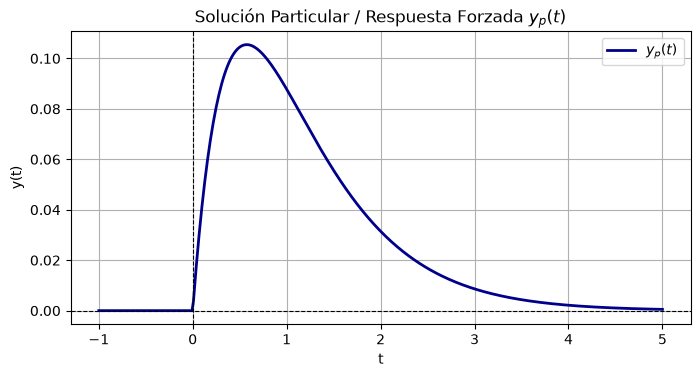

In [42]:
t = sp.Symbol('t', real=True)
y = sp.Function('y')(t)

# Definir lado izquierdo y derecho
lhs_A = 2*y.diff(t) + 3*y
rhs_A = sp.exp(-2*t) * sp.Heaviside(t)

# Resolver
y_gen_A = resolver_edo_fourier_plantilla(lhs_A, rhs_A, y, t)

PASO 1: Transformar el Lado Izquierdo al Dominio de Frecuencia



PASO 2: Transformar el Lado Derecho f(t)



PASO 3: Despejar Y(\omega)



PASO 4: Inversa de Fourier para la Solución Particular y_p(t)
-> Método de Residuos (Fórmula A del PDF para raíces simples):



PASO 5: Solución Complementaria y_c(t) y Solución General y(t)


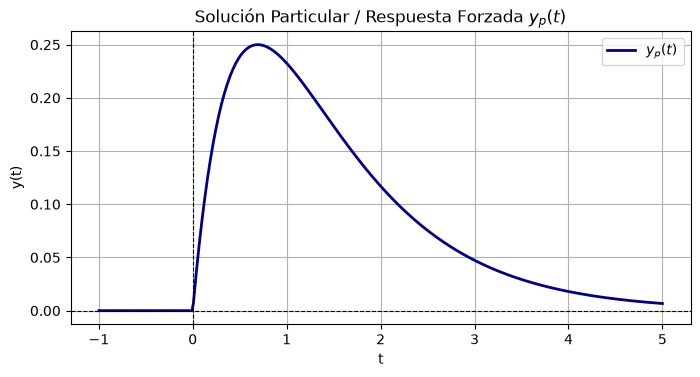

In [43]:
lhs_B = y.diff(t, 2) + 3*y.diff(t) + 2*y
rhs_B = sp.DiracDelta(t)

y_gen_B = resolver_edo_fourier_plantilla(lhs_B, rhs_B, y, t)

PASO 1: Transformar el Lado Izquierdo al Dominio de Frecuencia



PASO 2: Transformar el Lado Derecho f(t)



PASO 3: Despejar Y(\omega)



PASO 4: Inversa de Fourier para la Solución Particular y_p(t)
-> Método de Residuos (Fórmula A del PDF para raíces simples):



PASO 5: Solución Complementaria y_c(t) y Solución General y(t)


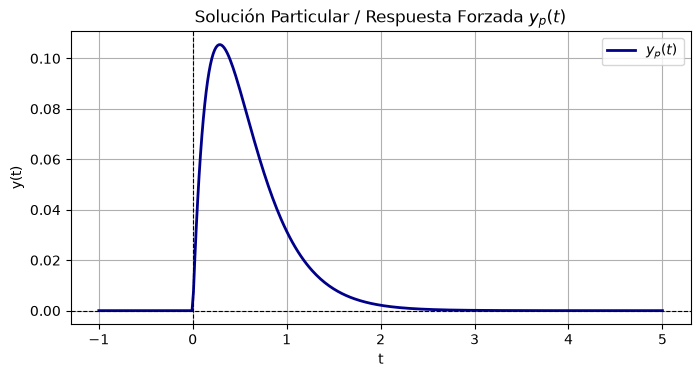

In [44]:
lhs_C = y.diff(t) + 4*y
rhs_C = sp.exp(-3*t) * sp.Heaviside(t)

y_gen_C = resolver_edo_fourier_plantilla(lhs_C, rhs_C, y, t)